# 8. Outside data: does knowing about war and epidemics help?

**Life Expectancy Predictor · notebook 8 of 8**

Notebooks 5 and 7 ended with a recommendation: the hard countries are hard because the 13 WHO inputs don't contain what makes them different, so the next step is outside data on **conflict**, **epidemics** and **reporting quality**. This notebook tests that recommendation. It is the project's own prediction about itself, and it gets the same honest treatment as everything else.

The short version: the recommendation was wrong. None of the three helped, and one made things worse. The rest of the notebook shows how we know, and what it means.

## Step 1: The outside data

**What we are looking for.** Three new inputs for every country-year, from sources the WHO table knows nothing about:

- **Conflict:** battle-related deaths from the Uppsala Conflict Data Program (UCDP), the standard academic source on armed conflict. Credited to the country the conflict is in.
- **Epidemics:** epidemic events and their deaths from EM-DAT, the international disaster database (cholera, Ebola, meningitis, measles outbreaks and so on).
- **Reporting quality:** two signals computed from the WHO file itself: what share of a country's inputs were blank or disguised blanks, and how jumpy its figures are from year to year. Noisy statistics should show up here.

`analysis/external_data.py` joins all of this to the WHO country-years. A country with no recorded conflict or epidemic gets zero, which is the honest reading.

In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)
outside = pd.read_csv(ROOT / "data" / "external" / "outside_data_by_country_year.csv")
print(f"{len(outside):,} country-years, {outside.Country.nunique()} countries, {outside.Year.min()}-{outside.Year.max()}")
print(f"Countries with any battle deaths: {(outside.groupby('Country').battle_deaths.sum() > 0).sum()}   "
      f"with any epidemic event: {(outside.groupby('Country').epidemic_events.sum() > 0).sum()}")
totals = outside.groupby("Country")[["battle_deaths", "epidemic_deaths"]].sum()
bd, ed = totals.battle_deaths.nlargest(6), totals.epidemic_deaths.nlargest(6)
pd.DataFrame({"Most battle deaths, 2000-2015": [f"{c}: {v:,}" for c, v in bd.items()],
              "Most epidemic deaths, 2000-2015": [f"{c}: {v:,}" for c, v in ed.items()]}, index=range(1, 7))

Project folder: nb
2,928 country-years, 183 countries, 2000-2015
Countries with any battle deaths: 63   with any epidemic event: 114


,"Most battle deaths, 2000-2015","Most epidemic deaths, 2000-2015"
1,"Syrian Arab Republic: 239,235","Burkina Faso: 8,626"
2,"Afghanistan: 95,491","Nigeria: 7,324"
3,"Iraq: 52,981","Haiti: 7,168"
4,"Ethiopia: 51,528","Democratic Republic of the Congo: 6,841"
5,"Eritrea: 50,092","Liberia: 4,852"
6,"Pakistan: 29,232","Zimbabwe: 4,694"


**How to read it.** The data covers every WHO country-year. A third of countries had some armed conflict in the period; nearly two thirds had at least one recorded epidemic. The two columns name the countries with the most deaths of each kind.

**What it means.** The signals are real and large where they occur: Syria's 239,000 battle deaths, Haiti's cholera epidemic after the 2010 earthquake. If conflict and epidemics are what the model is missing, these inputs should fix the countries where they happened.

**What's next and why.** Add them to the model, one family at a time, and score on unseen countries.

## Step 2: Five models, same honest test

**What we are looking for.** The deployed model (13 inputs) against four variants: + conflict, + epidemics, + reporting quality, and all together. Every variant uses the *same* five country-based folds, so the comparison is paired: each country is predicted unseen by every variant, and any difference is due to the inputs, not luck in the split. `analysis/outside_data_check.py` ran this; the results are read back here.

In [2]:
chk = results("outside_data_check")
v = chk["variants"]
tbl = pd.DataFrame({name: [r["inputs"], r["r2_mean"], r["oof_mae"], r["mae_hardest_18_of_base"], r["mae_other_countries"], r["fairness_gap"]]
                    for name, r in v.items()},
                   index=["Inputs", "R² on unseen countries", "Average miss (years)", "Miss on the 18 hardest countries",
                          "Miss on the other 165", "Developing-minus-developed gap"]).T
tbl

,Inputs,R² on unseen countries,Average miss (years),Miss on the 18 hardest countries,Miss on the other 165,Developing-minus-developed gap
base,13.0,0.9010,2.1387,4.761,1.853,0.410
+conflict,14.0,0.9010,2.1382,4.745,1.854,0.413
+epidemic,15.0,0.9013,2.1347,4.752,1.849,0.409
+reporting,15.0,0.8936,2.1950,4.891,1.901,0.453
+all,18.0,0.8929,2.2027,4.919,1.906,0.470


**How to read it.** One row per model. "Miss on the 18 hardest countries" is the average miss on the countries the base model found hardest (notebook 5), which is where outside data was supposed to help.

**What it means.**

- **Conflict and epidemics change nothing.** R² stays at 0.901; the average miss moves by a few thousandths of a year; the hardest 18 go from 4.76 to 4.75. Somalia, the worst country, goes from 11.45 to 11.44 years.
- **Reporting quality makes it worse.** The two signals cost 0.007 of R² and add 0.06 years to the average miss, and they widen the fairness gap from 0.41 to 0.45. Adding everything is worse still.

**What's next and why.** "A few thousandths of a year" could be a tiny real gain or pure noise. The next step tells them apart.

## Step 3: Is any of it more than noise?

**What we are looking for.** For each variant, the change in each country's miss compared with the base model. Redraw the set of countries 2,000 times (a paired bootstrap) to get a range the true change is likely to be in. If the range includes zero, the change is noise.

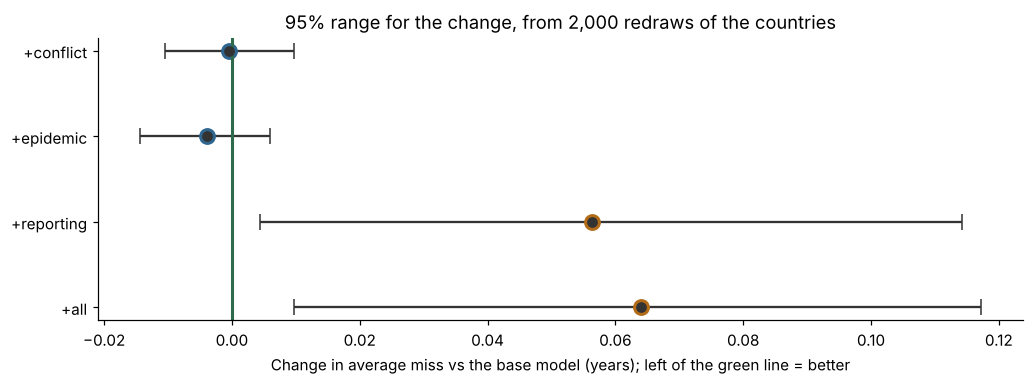

,Mean change (years),95% range,Countries better by >0.05,Countries worse by >0.05
+conflict,-0.0005,-0.010 to +0.010,30,32
+epidemic,-0.0039,-0.014 to +0.006,29,33
+reporting,0.0564,+0.004 to +0.114,60,80
+all,0.064,+0.010 to +0.117,59,81


In [3]:
boot = chk["paired_bootstrap_vs_base"]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
names = list(boot)
means = [boot[n]["mean_change_years"] for n in names]
lo = [boot[n]["ci95"][0] for n in names]; hi = [boot[n]["ci95"][1] for n in names]
colors = ["#B26B16" if l > 0 else "#2F6690" for l in lo]
ax.errorbar(means, range(len(names)), xerr=[np.subtract(means, lo), np.subtract(hi, means)], fmt="o", color="#333", capsize=5, lw=1.5)
for i, (m, c) in enumerate(zip(means, colors)): ax.plot(m, i, "o", color=c, ms=10)
ax.axvline(0, color="#2E6A4C", lw=2)
ax.set(yticks=range(len(names)), yticklabels=names, xlabel="Change in average miss vs the base model (years); left of the green line = better",
       title="95% range for the change, from 2,000 redraws of the countries")
ax.invert_yaxis(); plt.tight_layout(); plt.show()
pd.DataFrame({n: [b["mean_change_years"], f"{b['ci95'][0]:+.3f} to {b['ci95'][1]:+.3f}", b["countries_improved"], b["countries_worsened"]] for n, b in boot.items()},
             index=["Mean change (years)", "95% range", "Countries better by >0.05", "Countries worse by >0.05"]).T

**How to read it.** Each dot is a variant's average change; the bar is the range it would land in 95% of the time. A bar that crosses the green zero line means "could be nothing".

**What it means.** Conflict and epidemic data are nothing: their ranges sit squarely on zero, and they make about as many countries slightly better as slightly worse. Reporting quality is *reliably* harmful: its whole range is above zero, and it worsens 80 countries while improving 60.

**What's next and why.** A null result is only useful if you understand it. Why doesn't knowing about a war help?

## Step 4: Why conflict data adds nothing

**What we are looking for.** Whether the model's errors are related to conflict at all. If the base model were systematically too optimistic about countries at war, the signed miss (prediction minus truth) would be positive in conflict years. And whether the WHO inputs already "know" about the war.

In [4]:
oof = pd.read_csv("oof_predictions.csv").merge(outside, on=["Country", "Year"])
clean = pd.read_csv(ROOT / "data" / "clean_data.csv")[["Country", "Year", "Adult_Mortality", "HIV_AIDS"]]
oof = oof.merge(clean, on=["Country", "Year"])
oof["signed"] = oof["oof_prediction"] - oof["truth"]
oof["conflict"] = np.where(oof.battle_deaths == 0, "no conflict", np.where(oof.battle_deaths < 1000, "under 1,000 deaths", "1,000+ deaths"))

# Re-run the "+conflict" model out of fold here, so its per-row misses can be grouped the same way.
from data_prep import get_unclipped_df, FoldWinsorizer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
df = get_unclipped_df(config).merge(outside[["Country", "Year", "log_battle_deaths"]], on=["Country", "Year"])
cols = config.predictor_columns + ["log_battle_deaths"]
X, y, groups = df[cols].to_numpy(), df[config.target_column].to_numpy(), df["Country"].to_numpy()
mp = config.model_params
pc = np.zeros(len(y))
for tr, te in GroupKFold(5).split(X, y, groups):
    m = Pipeline([("clip", FoldWinsorizer([tuple(config.winsorize_limits.get(c, (0, 0))) for c in cols])),
                  ("rf", RandomForestRegressor(n_estimators=mp["n_estimators"], random_state=mp["random_state"], n_jobs=-1))]).fit(X[tr], y[tr])
    pc[te] = m.predict(X[te])
oof = oof.merge(pd.DataFrame({"Country": groups, "Year": df["Year"].values, "signed_with_conflict": pc - y}), on=["Country", "Year"])

g = oof.groupby("conflict").agg(country_years=("signed", "size"),
                                signed_miss_base=("signed", "mean"), signed_miss_with_conflict=("signed_with_conflict", "mean"),
                                miss_base=("signed", lambda s: s.abs().mean()), miss_with_conflict=("signed_with_conflict", lambda s: s.abs().mean()),
                                adult_mortality=("Adult_Mortality", "mean")).loc[["no conflict", "under 1,000 deaths", "1,000+ deaths"]]
display(g.round(2))
r = np.corrcoef(oof.log_battle_deaths, oof.signed)[0, 1]
print(f"Correlation between battle deaths and the base model's signed miss, over all rows: {r:+.3f}  (0 = unrelated)")

,country_years,signed_miss_base,signed_miss_with_conflict,miss_base,miss_with_conflict,adult_mortality
conflict,,,,,,
no conflict,2488,-0.01,-0.01,2.11,2.10,159.30
"under 1,000 deaths",319,0.14,0.11,2.18,2.22,189.79
"1,000+ deaths",121,1.38,1.31,2.57,2.62,211.83


Correlation between battle deaths and the base model's signed miss, over all rows: +0.071  (0 = unrelated)


**How to read it.** Country-years grouped by how much fighting there was. A signed miss above zero means the model predicts too long a life. The columns compare the base model with the "+conflict" model on the same rows; the last column is the WHO's adult-mortality figure.

**What it means.** Three things:

1. **There is a small conflict-shaped error.** In the 121 heaviest conflict years (4% of rows), the base model is about 1.4 years too optimistic. In lighter conflict years and in peace it is unbiased. So the idea was not silly: war does cost more than the model expects, a little.
2. **But the conflict input doesn't fix it.** With battle deaths as an input, the signed miss in those 121 rows barely moves. The forest cannot learn much from 121 rows spread over a dozen countries when the same countries' other years, with the same statistics, say "no extra penalty". The signal is real but too thin to learn from.
3. **The WHO inputs already see most of the war.** Adult mortality is far higher in the 1,000+ deaths group. When a country is in crisis, its death statistics say so, and the model reads them; the 1.4 years is what is left after that.

The same logic applies to epidemics: a cholera outbreak shows up in under-five deaths and adult mortality before it shows up in a disaster database.

**What's next and why.** The reporting-quality result deserves its own explanation, because it was the project's best guess for the fairness gap.

## Step 5: Why reporting quality made it worse

**What we are looking for.** The two reporting signals are per-country constants (the same value in all 16 of a country's rows). What does the model do with a per-country constant?

In [5]:
imp = chk["outside_input_importance_in_all"]
display(pd.Series(imp, name="Change in miss when scrambled (years); positive = the model relied on it").round(4).to_frame())
rq = outside.groupby("Country")[["inputs_filled_pct", "input_volatility"]].first()
base_miss = pd.Series(chk["per_country"]["base"])
print(f"Correlation of a country's base miss with its filled-in share: {np.corrcoef(rq.inputs_filled_pct, base_miss[rq.index])[0,1]:+.3f}")
print(f"Correlation of a country's base miss with its input volatility: {np.corrcoef(rq.input_volatility, base_miss[rq.index])[0,1]:+.3f}")

,Change in miss when scrambled (years); positive = the model relied on it
log_battle_deaths,0.0025
epidemic_events,-0.0013
log_epidemic_deaths,0.0007
inputs_filled_pct,-0.0097
input_volatility,0.0109


Correlation of a country's base miss with its filled-in share: +0.228
Correlation of a country's base miss with its input volatility: +0.164


**How to read it.** The first table is permutation importance for the five outside inputs inside the "+all" model (scramble one, see how much worse the predictions get). Below it, whether the two reporting signals are related to how badly a country is predicted.

**What it means.** The reporting signals are weakly related to error (correlations of 0.23 and 0.16): countries with thinner, jumpier data are missed a little more, as the fairness check in notebook 6 suggested. So there is something there. But a random forest cannot use "trust this row less"; it can only split on values. And these are per-country constants with 183 distinct values, which makes them *country fingerprints*: a tree can split on "volatility = 0.249" and effectively say "this is Sierra Leone". That helps on the training countries and hurts on unseen ones, which is exactly the pattern in Step 2. The honest test caught it; a random-row test would have rewarded it.

**What's next and why.** Put the result in its place.

## Step 6: What this changes

**What we are looking for.** The conclusion of the project after this test, and a revised "what's next".

**What it means.** The project's recommendation was tested and did not survive, and that is the most useful kind of result a portfolio project can show. Three things are now established, each by a fair test on unseen countries:

| Claim | Evidence | Verdict |
| --- | --- | --- |
| A better algorithm would help | Four algorithms raced (notebook 7) | No: tree models tie, all fail on the same countries |
| Correcting the predictions afterwards would help | Linear and isotonic corrections, cross-fitted (notebook 5) | No: worse |
| Outside data on conflict, epidemics and reporting quality would help | This notebook | No: conflict and epidemics add nothing the WHO inputs don't already say; reporting signals act as country fingerprints and hurt |

The 13 WHO inputs carry what *can* be carried about a country's life expectancy at this level of detail. The remaining error in the hard countries is not a missing variable that another table can supply. It is country-specific: Somalia's statistics are too thin to describe it; Korea and Cuba live longer than countries with similar numbers for reasons (diet, health-system design, culture) that no national statistic captures.

**What's next and why.** The honest answer to "how would you improve this?" is now narrower and better:

- **Not** another data source of the same kind. Three were tried.
- **Possibly** a different *unit*: sub-national data (regions within countries) would give the model many more examples of the extreme cases it sees too few of, and would make Somalia-sized misses visible as a spread rather than a single number.
- **Definitely** honesty about the limit: a model at R² 0.90 with a per-group uncertainty band that keeps its promise is the deliverable, and the project page says so.

## Summary

| Question | Answer |
| --- | --- |
| Did conflict data help? | No: −0.001 years, range −0.010 to +0.010 |
| Did epidemic data help? | No: −0.004 years, range −0.014 to +0.006 |
| Did reporting-quality signals help? | No, they hurt: +0.056 years, range +0.004 to +0.114; fairness gap 0.41 → 0.45 |
| Why not? | Heavy-conflict years are only 4% of rows, and the death statistics already reflect most of the crisis; per-country constants become fingerprints |
| What would still be worth trying? | Sub-national data; otherwise the limit is reached |